# 05 - Light GNN on weekly graphs

Question: does a light GraphSAGE on **one user-PC graph per week** beat (a) the same network **without edges** (MLP) and (b) the best tabular baselines (random forest and XGBoost on feature set W2, notebook 04)?

- **Graph.** Per week, one node per user-week and one per PC used that week; an edge joins a user-week to each PC it logged on to (both directions). Built only from that week's Logon events, no edge between weeks; all weeks are one disjoint graph.
- **Features.** User nodes: the W2 features (signed log on `dev_*`, `log1p` on the others, then a scaler fit on the **training fold's** rows only) plus `has_history`. PC nodes: type flag and `log(users on that PC that week)`. Each user's first 4 active weeks (warm-up) stay in the graph as neighbours with `has_history = 0` and zero history columns, but are **never in the loss or in evaluation**, exactly the rows notebook 04 dropped.
- **Training.** Full-batch Adam, weighted cross-entropy with class weight sqrt(neg/pos) (capped at 50), 2 layers, hidden 64, dropout 0.3, last-epoch model, no checkpoint selection. Epoch counts were chosen **once** by a pilot on the training users of repeat 0 fold 0 (inner validation split by user) and are fixed in `config.yaml`. Test users' nodes are in the graph (transductive) but their labels are never used.
- **Evaluation.** Same 25 user-level folds, same tie-aware metrics and alert budgets as notebook 04; RF-W2 and XGBoost-W2 scores are read from `results/weekly_v2_oof_scores.parquet` and checked to cover exactly the same rows. Nothing is tuned on test folds.

In [1]:
%load_ext autoreload
%autoreload 2
import json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, average_precision_score

from itgnn.data import load_config, prepare
from itgnn.evaluation import make_folds, evaluate_scores, alert_budget
from itgnn.weekly_features import add_history_features, drop_warmup
from itgnn.weekly_gnn import choose_epoch, pilot_curves, train_scores
from itgnn.weekly_graph import build_weekly_graph, fold_masks, node_features
from itgnn.windows import load_attack_windows, label_weeks, make_weekly_features

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
cfg = load_config("configs/config.yaml")
GC = cfg["gnn"]
SEED, QS = cfg["seed"], [0.25, 0.5, 1, 2]
EPOCHS = {"MLP": GC["epochs"]["mlp"], "GraphSAGE": GC["epochs"]["sage"]}
CONV = {"MLP": "mlp", "GraphSAGE": "sage"}
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.width = 200
pd.options.display.max_columns = 50
pd.options.display.max_rows = 200
print("device: cpu (torch", torch.__version__, "CPU build) | threads:", torch.get_num_threads(), "| epochs:", EPOCHS)

d = prepare(cfg)
users, labels = d["users"], d["labels"]
folds = make_folds(users, labels, cfg["cv"]["n_splits"], cfg["cv"]["n_repeats"], SEED)
windows = load_attack_windows(cfg["raw_dir"])
ins = pd.read_csv(Path(cfg["raw_dir"]) / "answers" / "insiders.csv")
scen = ins[ins["dataset"].astype(str) == "4.2"].set_index("user")["scenario"]
SCEN = sorted(scen.unique())
full = make_weekly_features(d["logon"], d["device"], d["file"], users)
full["label"] = label_weeks(full, windows)
full = add_history_features(full, d["logon"])
g = build_weekly_graph(full, d["logon"])
y = g.rows["label"].to_numpy()
weekly = drop_warmup(full)  # the rows notebook 04 used

/home/nothing/insider-threat-gnn/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


device: cpu (torch 2.15.0+cpu CPU build) | threads: 10 | epochs: {'MLP': 188, 'GraphSAGE': 224}


## 1. Dataset and graph sizes

In [2]:
n_pc = g.n_node - g.n_user
users_per_pc = np.exp(g.pc_logn).round().astype(int)
h = g.rows["has_history"].to_numpy()
print(f"user nodes: {g.n_user:,} (warm-up, neighbours only: {(~h).sum():,}; scored rows: {h.sum():,} = notebook 04's {len(weekly):,})")
print(f"PC nodes (PC, week): {n_pc:,} | undirected edges: {g.edge_index.shape[1] // 2:,} | weeks: {g.rows['week_start'].nunique()}")
per_week = pd.Series(g.node_week).value_counts()
print("nodes per week: min", per_week.min(), "median", int(per_week.median()), "max", per_week.max())
print(f"PC-week nodes with exactly 1 user: {(users_per_pc == 1).mean():.1%} | max users on one PC-week: {users_per_pc.max()} | mean degree of user nodes: {g.edge_index.shape[1] / 2 / g.n_user:.2f}")
print(f"attack weeks: {int(y[h].sum())} of {h.sum():,} scored rows ({y[h].mean():.2%}) | insiders: {len(labels)}")
tab = pd.DataFrame({"insiders": scen.value_counts(), "attack weeks": weekly[weekly['label'] == 1].groupby(lambda i: weekly.loc[i, 'user']).size().groupby(scen).sum()}).fillna(0).astype(int)
display(tab)
print("insiders with an attack week among scored rows:", weekly.loc[weekly['label'] == 1, 'user'].nunique(), "of", len(labels))

user nodes: 67,238 (warm-up, neighbours only: 4,000; scored rows: 63,238 = notebook 04's 63,238)
PC nodes (PC, week): 67,375 | undirected edges: 112,408 | weeks: 73
nodes per week: min 149 median 1878 max 2002
PC-week nodes with exactly 1 user: 59.6% | max users on one PC-week: 153 | mean degree of user nodes: 1.67
attack weeks: 322 of 63,238 scored rows (0.51%) | insiders: 70


,insiders,attack weeks
scenario,,
1,30,52
2,30,260
3,10,10


insiders with an attack week among scored rows: 70 of 70


## 2. Pilot: choosing the number of epochs

Training users of **repeat 0 fold 0** only (800 users). Three stratified 80/20 splits of those users; the scaler and the loss use the inner-train users, the PR-AUC is computed on the inner-validation users (their nodes stay in the graph, labels unused). Rule, the same for both models: take the mean over splits of the validation PR-AUC per epoch, smooth with a trailing 5-epoch mean, and pick the **earliest epoch within 0.01 of the best smoothed value**. The curves were computed once by `pilot_curves` (about 15 minutes) and saved to `results/gnn_lite_pilot_curves.parquet`; set `RERUN_PILOT = True` to recompute. Only 800 users with about 11 insiders per validation split make these curves noisy, and the 300-epoch cap was fixed beforehand.

chosen by the pilot: {'MLP': 188, 'GraphSAGE': 224} | in config.yaml: {'MLP': 188, 'GraphSAGE': 224}


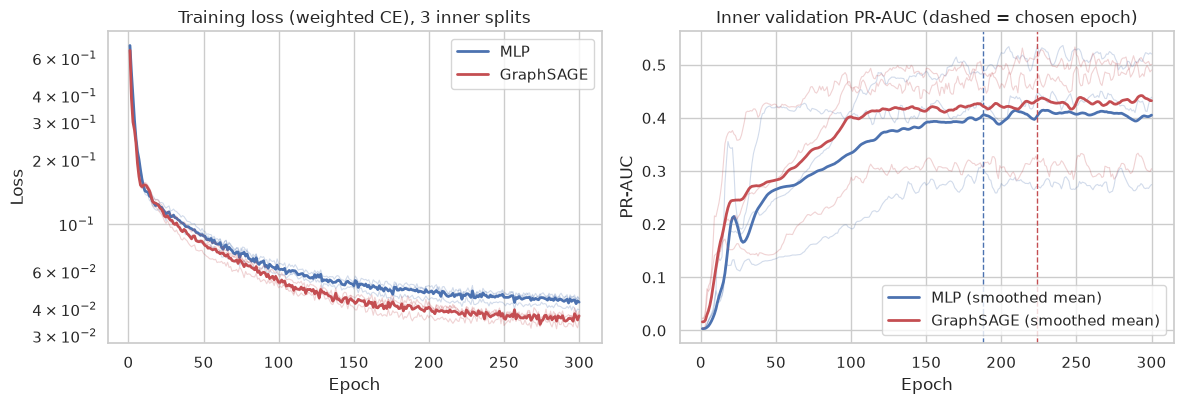

In [3]:
RERUN_PILOT = False
pf = Path("results/gnn_lite_pilot_curves.parquet")
if RERUN_PILOT or not pf.exists():
    curves = pd.concat([pilot_curves(g, folds[0]["train"], GC, c, SEED) for c in ["mlp", "sage"]], ignore_index=True)
    curves.to_parquet(pf, index=False)
curves = pd.read_parquet(pf)
chosen = {m: choose_epoch(curves[curves["model"] == c], GC["pilot"]["smooth"], GC["pilot"]["tolerance"]) for m, c in CONV.items()}
print("chosen by the pilot:", chosen, "| in config.yaml:", EPOCHS)
assert chosen == EPOCHS, "config.yaml epochs differ from the pilot's choice"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m, c in CONV.items():
    cv = curves[curves["model"] == c]
    col = "#4c72b0" if m == "MLP" else "#c44e52"
    for s, gs in cv.groupby("split"):
        axes[0].plot(gs["epoch"], gs["loss"], color=col, alpha=0.25, lw=0.8)
        axes[1].plot(gs["epoch"], gs["val_ap"], color=col, alpha=0.25, lw=0.8)
    axes[0].plot(cv.groupby("epoch")["loss"].mean(), color=col, lw=2, label=m)
    sm = cv.groupby("epoch")["val_ap"].mean().rolling(GC["pilot"]["smooth"], min_periods=1).mean()
    axes[1].plot(sm, color=col, lw=2, label=f"{m} (smoothed mean)")
    axes[1].axvline(chosen[m], color=col, ls="--", lw=1)
axes[0].set(title="Training loss (weighted CE), 3 inner splits", xlabel="Epoch", ylabel="Loss", yscale="log"); axes[0].legend()
axes[1].set(title="Inner validation PR-AUC (dashed = chosen epoch)", xlabel="Epoch", ylabel="PR-AUC"); axes[1].legend()
plt.tight_layout(); plt.show()

## 3. Cross-validation (25 folds)

Per fold: scaler fit on the training users' scored rows, loss on those rows only, scores for the test users' scored rows. Epochs are the fixed values above and the seed is the config seed for every fold.

In [4]:
y_all = y
RERUN_CV = False  # the 25-fold run takes about 75 min on CPU; True retrains, False loads the saved scores
of, info_f = Path("results/gnn_lite_oof_scores.parquet"), Path("results/gnn_lite_run_info.json")
if RERUN_CV or not of.exists():
    oof_parts, times = [], {m: 0.0 for m in CONV}
    t_all = time.time()
    for f in folds:
        tr, te = fold_masks(g, f["train"], f["test"])
        x, _ = node_features(g, tr)
        for name, conv in CONV.items():
            t0 = time.time()
            s, _ = train_scores(x, g.edge_index, y_all, np.flatnonzero(tr), EPOCHS[name], conv, GC, SEED)
            times[name] += time.time() - t0
            s = s[: g.n_user][te]
            oof_parts.append(pd.DataFrame({"user": g.rows.loc[te, "user"].to_numpy(), "week_start": g.rows.loc[te, "week_start"].to_numpy(),
                                           "repeat": f["repeat"], "fold": f["fold"], "model": name, "score": s, "label": y_all[te]}))
        if f["fold"] == 4:
            print(f"repeat {f['repeat']} done, {time.time() - t_all:.0f}s elapsed", flush=True)
    gnn_oof = pd.concat(oof_parts, ignore_index=True)
    gnn_oof.to_parquet(of, index=False)
    json.dump({"total_min": (time.time() - t_all) / 60, "train_min": {m: v / 60 for m, v in times.items()}, "device": "cpu"}, open(info_f, "w"))
gnn_oof = pd.read_parquet(of)
print("out-of-fold scores:", of, gnn_oof.shape)
print("run info:", json.load(open(info_f)) if info_f.exists() else "not recorded")

out-of-fold scores: results/gnn_lite_oof_scores.parquet (632380, 7)
run info: {'total_min': 75.4, 'train_min': None, 'device': 'cpu', 'note': 'first full execution: derived from file timestamps (notebook start 18:23:02 to OOF file written 19:38:26, includes about 1 min of setup); per-model split was not recorded'}


## 4. Same rows and folds as the baselines

RF W2 and XGBoost W2 scores come from notebook 04's saved file. Before comparing anything we check that they cover exactly the same (user, week, repeat, fold) rows with the same labels as the GNN scores.

In [5]:
KEYS = ["user", "week_start", "repeat", "fold"]
base = pd.read_parquet("results/weekly_v2_oof_scores.parquet")
base = base[base["model"].isin(["RF W2", "XGB W2"])]
ref = gnn_oof[gnn_oof["model"] == "GraphSAGE"][KEYS + ["label"]].sort_values(KEYS).reset_index(drop=True)
for m in ["RF W2", "XGB W2"]:
    b = base[base["model"] == m][KEYS + ["label"]].sort_values(KEYS).reset_index(drop=True)
    pd.testing.assert_frame_equal(b, ref, check_dtype=False)
for m in ["MLP"]:
    pd.testing.assert_frame_equal(gnn_oof[gnn_oof["model"] == m][KEYS + ["label"]].sort_values(KEYS).reset_index(drop=True), ref)
print(f"all four models are scored on the same {len(ref) // 5:,} rows x 5 repeats, same labels: OK")
oof = pd.concat([gnn_oof, base], ignore_index=True)
ORDER = ["MLP", "GraphSAGE", "RF W2", "XGB W2"]
rows = []
for (m, r, fo), gf in oof.groupby(["model", "repeat", "fold"]):
    ev = evaluate_scores(gf["label"].to_numpy(), gf["score"].to_numpy(), k=100)
    rows.append({"model": m, "repeat": r, "fold": fo, "pr_auc": ev["pr_auc"], "roc_auc": ev["roc_auc"]})
results = pd.DataFrame(rows)
prev = y[h].mean()

all four models are scored on the same 63,238 rows x 5 repeats, same labels: OK


## 5. Results: week-level PR-AUC and ROC-AUC

Mean ± std over the 25 folds on the scored rows (PR-AUC floor = prevalence). Then repeat 0 fold 0 alone, the only test fold no choice in this notebook ever saw (the epoch counts came from that fold's training users; its test users were untouched).

In [6]:
S = results.groupby("model")[["pr_auc", "roc_auc"]].agg(["mean", "std"]).loc[ORDER]
display(pd.DataFrame({m.replace("_", "-").upper(): S[m].apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1) for m in ["pr_auc", "roc_auc"]}))
print(f"prevalence: {prev:.4f}")
print("repeat 0 fold 0 only:")
display(results[(results["repeat"] == 0) & (results["fold"] == 0)].set_index("model").loc[ORDER, ["pr_auc", "roc_auc"]])

,PR-AUC,ROC-AUC
model,,
MLP,0.395 ± 0.075,0.985 ± 0.008
GraphSAGE,0.430 ± 0.073,0.985 ± 0.009
RF W2,0.503 ± 0.071,0.982 ± 0.013
XGB W2,0.458 ± 0.080,0.986 ± 0.012


prevalence: 0.0051
repeat 0 fold 0 only:


,pr_auc,roc_auc
model,,
MLP,0.348,0.986
GraphSAGE,0.443,0.988
RF W2,0.463,0.988
XGB W2,0.435,0.983


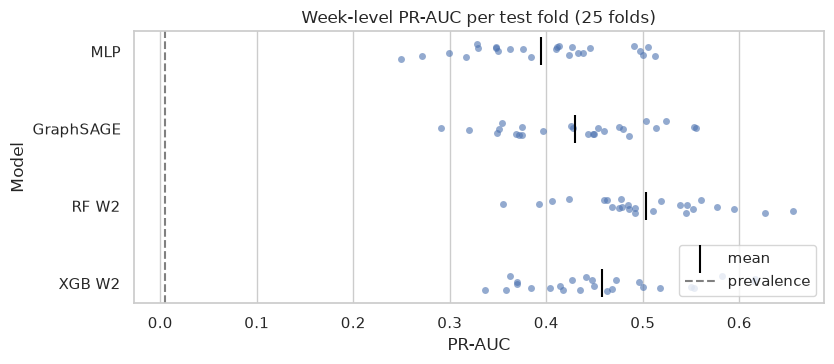

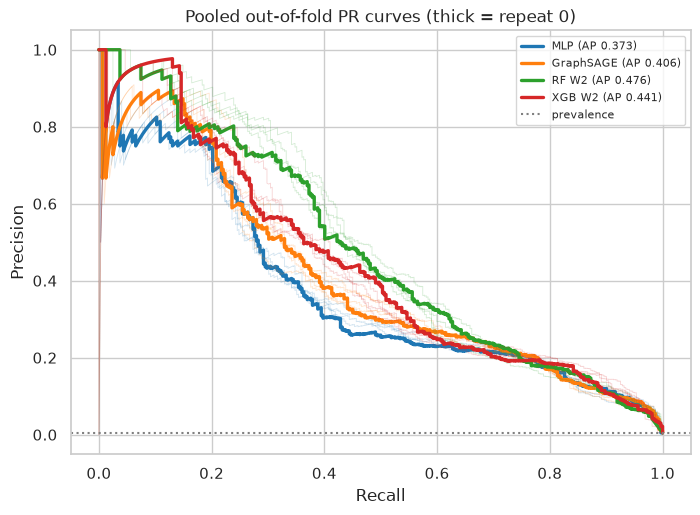

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
sns.stripplot(data=results, y="model", x="pr_auc", order=ORDER, orient="h", alpha=0.6, size=5, ax=ax)
ax.scatter(results.groupby("model")["pr_auc"].mean().loc[ORDER].values, range(len(ORDER)), marker="|", s=400, color="black", zorder=3, label="mean")
ax.axvline(prev, color="gray", ls="--", label="prevalence")
ax.set(title="Week-level PR-AUC per test fold (25 folds)", xlabel="PR-AUC", ylabel="Model"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 5.5))
pal = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))
for name in ORDER:
    for r in sorted(oof["repeat"].unique()):
        sub = oof[(oof["model"] == name) & (oof["repeat"] == r)]
        p, rc, _ = precision_recall_curve(sub["label"], sub["score"])
        ax.plot(rc, p, color=pal[name], lw=2.4 if r == 0 else 0.6, alpha=1 if r == 0 else 0.2,
                label=f"{name} (AP {average_precision_score(sub['label'], sub['score']):.3f})" if r == 0 else None)
ax.axhline(prev, color="gray", ls=":", label="prevalence")
ax.set(title="Pooled out-of-fold PR curves (thick = repeat 0)", xlabel="Recall", ylabel="Precision"); ax.legend(fontsize=8)
plt.show()

## 6. Paired differences (PR-AUC)

Same folds and rows for every model, so we subtract fold by fold. Repeated-CV folds are correlated, so the std understates the uncertainty: descriptive only, not a significance test.

In [8]:
pv = results.pivot_table(index=["repeat", "fold"], columns="model", values="pr_auc")
rows = {}
for b in ["MLP", "RF W2", "XGB W2"]:
    dl = pv["GraphSAGE"] - pv[b]
    rows[f"GraphSAGE - {b}"] = {"mean diff": dl.mean(), "std": dl.std(), "folds where GraphSAGE wins": f"{(dl > 0).mean():.0%}", "repeat 0 fold 0": dl.loc[(0, 0)]}
display(pd.DataFrame(rows).T)

,mean diff,std,folds where GraphSAGE wins,repeat 0 fold 0
GraphSAGE - MLP,0.035,0.021,100%,0.095
GraphSAGE - RF W2,-0.073,0.044,0%,-0.020
GraphSAGE - XGB W2,-0.028,0.057,28%,0.008


## 7. Alert budget

In each test fold the top q% of scored user-weeks are flagged (ties at random, fixed seed); per repeat the 5 folds are pooled. **Caught** = insiders with at least one attack week flagged (all 70 insiders are eligible, none was lost to the warm-up); **normal users flagged** = distinct normal users with any week flagged. Mean ± std over 5 repeats. The first check recomputes the RF-W2 / XGBoost-W2 budget with the shared `alert_budget` function and compares it with notebook 04's printed numbers.

In [9]:
bud = alert_budget(oof, labels, scen.to_dict(), QS, SEED)
NB4 = {"RF W2": {0.25: (51.4, 3.2), 0.5: (56.6, 9.2), 1: (61.2, 18.2), 2: (65.4, 35.6)},
       "XGB W2": {0.25: (48.0, 2.8), 0.5: (52.6, 5.4), 1: (56.6, 10.2), 2: (62.6, 30.2)}}
m4 = bud.groupby(["model", "q%"])[["caught", "normal flagged"]].mean()
for mm, byq in NB4.items():
    for q, (c, n) in byq.items():
        assert (round(m4.loc[(mm, q), "caught"], 1), round(m4.loc[(mm, q), "normal flagged"], 1)) == (c, n), (mm, q)
print("alert_budget reproduces notebook 04's RF W2 and XGB W2 means (caught / normal flagged) at all four budgets: OK")
agg = bud.groupby(["model", "q%"]).agg(["mean", "std"])
fmt = lambda c: agg[c].apply(lambda r: f"{r['mean']:.1f} ± {r['std']:.1f}", axis=1)
display(pd.DataFrame({"caught / 70": fmt("caught"), "normal flagged / 930": fmt("normal flagged"), "weeks flagged": fmt("weeks flagged")}).reindex(ORDER, level=0))

alert_budget reproduces notebook 04's RF W2 and XGB W2 means (caught / normal flagged) at all four budgets: OK


caught / 70 normal flagged / 930 weeks flagged
model     q%                                                  
MLP       0.250  53.2 ± 2.0            9.2 ± 2.6   160.4 ± 0.5
          0.500  55.4 ± 1.5           13.6 ± 2.9   318.8 ± 0.4
          1.000  57.4 ± 0.9           18.6 ± 1.7   634.6 ± 0.9
          2.000  61.0 ± 1.2           32.6 ± 1.8  1267.2 ± 0.8
GraphSAGE 0.250  52.2 ± 2.3            9.2 ± 2.4   160.4 ± 0.5
          0.500  55.0 ± 1.9           14.2 ± 1.9   318.8 ± 0.4
          1.000  57.0 ± 1.4           23.4 ± 2.9   634.6 ± 0.9
          2.000  62.2 ± 1.1           40.8 ± 3.6  1267.2 ± 0.8
RF W2     0.250  51.4 ± 2.3            3.2 ± 0.4   160.4 ± 0.5
          0.500  56.6 ± 1.7            9.2 ± 1.1   318.8 ± 0.4
          1.000  61.2 ± 0.8           18.2 ± 3.6   634.6 ± 0.9
          2.000  65.4 ± 0.9           35.6 ± 4.6  1267.2 ± 0.8
XGB W2    0.250  48.0 ± 3.1            2.8 ± 0.8   160.4 ± 0.5
          0.500  52.6 ± 0.9            5.4 ± 0.5   318.8 ± 0.4
          1.000  56.6 ± 1.3           10.2 ± 1.8   634.6 ± 0.9
          2.000  62.6 ± 1.3           30.2 ± 6.8  1267.2 ± 0.8

## 8. Per scenario

Insiders caught per scenario (mean over 5 repeats; 30, 30 and 10 insiders) and week-level recall (share of that scenario's attack weeks flagged, mean over repeats).

In [10]:
m = bud.groupby(["model", "q%"]).mean(numeric_only=True)
aw = tab["attack weeks"]
cau = m[[f"caught s{s}" for s in SCEN]].unstack("q%").reindex(ORDER)
print("insiders caught per scenario (eligible: s1=30, s2=30, s3=10)")
display(cau.swaplevel(axis=1).reindex(columns=[(q, f"caught s{s}") for s in SCEN for q in QS]))
rec = pd.concat({f"week recall s{s}": m[f"attack weeks s{s}"] / aw[s] for s in SCEN}, axis=1).unstack("q%").reindex(ORDER)
print("week-level recall per scenario")
display(rec.swaplevel(axis=1).reindex(columns=[(q, f"week recall s{s}") for s in SCEN for q in QS]))

insiders caught per scenario (eligible: s1=30, s2=30, s3=10)


q%,0.250,0.500,1.000,2.000,0.250,0.500,1.000,2.000,0.250,0.500,1.000,2.000
,caught s1,caught s1,caught s1,caught s1,caught s2,caught s2,caught s2,caught s2,caught s3,caught s3,caught s3,caught s3
model,,,,,,,,,,,,
MLP,24.800,26.000,27.000,28.400,24.800,25.400,25.800,27.200,3.600,4.000,4.600,5.400
GraphSAGE,24.200,25.200,26.200,27.400,24.200,25.200,26.000,28.200,3.800,4.600,4.800,6.600
RF W2,23.000,27.000,28.800,29.600,23.400,24.000,26.400,29.200,5.000,5.600,6.000,6.600
XGB W2,20.200,23.600,26.400,28.800,24.000,25.200,26.200,28.600,3.800,3.800,4.000,5.200


week-level recall per scenario


q%,0.250,0.500,1.000,2.000,0.250,0.500,1.000,2.000,0.250,0.500,1.000,2.000
,week recall s1,week recall s1,week recall s1,week recall s1,week recall s2,week recall s2,week recall s2,week recall s2,week recall s3,week recall s3,week recall s3,week recall s3
model,,,,,,,,,,,,
MLP,0.619,0.700,0.742,0.812,0.196,0.294,0.480,0.734,0.360,0.400,0.460,0.540
GraphSAGE,0.615,0.669,0.735,0.792,0.222,0.345,0.525,0.742,0.380,0.460,0.480,0.660
RF W2,0.531,0.715,0.858,0.938,0.305,0.416,0.552,0.711,0.500,0.560,0.600,0.660
XGB W2,0.485,0.604,0.731,0.869,0.271,0.398,0.518,0.755,0.380,0.380,0.400,0.520


## 9. Repeat 0 fold 0 alone

One test fold (200 users, 14 insiders): the budget is for that fold only, so the counts are out of its insiders, and there is no variation to report.

In [11]:
sub = oof[(oof["repeat"] == 0) & (oof["fold"] == 0)]
test_ins = set(f for f in folds[0]["test"] if f in labels)
b0 = alert_budget(sub, labels, scen.to_dict(), QS, SEED)
print(f"test users: {len(folds[0]['test'])}, insiders among them: {len(test_ins)}, scored rows: {len(sub) // 4:,}")
display(b0.pivot(index="model", columns="q%", values=["caught", "normal flagged"]).reindex(ORDER))

test users: 200, insiders among them: 14, scored rows: 12,849


caught                   normal flagged                  
q%         0.250 0.500 1.000 2.000          0.250 0.500 1.000 2.000
model                                                              
MLP            9     9    10    10              0     1     1     1
GraphSAGE      9     9     9    10              0     1     1     5
RF W2          9     9    11    11              0     0     2     5
XGB W2        10    10    10    11              0     0     1     6

## 10. Seed variance (repeat 0 fold 0)

Each model is retrained with 5 different seeds on this one fold with the same fixed epochs. This only measures how much a single run moves with the initialisation; nothing is tuned from it.

In [12]:
tr0, te0 = fold_masks(g, folds[0]["train"], folds[0]["test"])
x0, _ = node_features(g, tr0)
seed_parts, seed_ap = [], []
t0 = time.time()
for name, conv in CONV.items():
    for i in range(GC["n_seeds"]):
        s, _ = train_scores(x0, g.edge_index, y_all, np.flatnonzero(tr0), EPOCHS[name], conv, GC, SEED + i)
        s = s[: g.n_user][te0]
        seed_ap.append({"model": name, "seed": SEED + i, "pr_auc": evaluate_scores(y_all[te0], s, k=100)["pr_auc"]})
        seed_parts.append(pd.DataFrame({"user": g.rows.loc[te0, "user"].to_numpy(), "week_start": g.rows.loc[te0, "week_start"].to_numpy(),
                                        "repeat": 0, "fold": 0, "model": f"{name}|{SEED + i}", "score": s, "label": y_all[te0]}))
seed_time = time.time() - t0
sb = alert_budget(pd.concat(seed_parts), labels, scen.to_dict(), QS, SEED)
sb["model"] = sb["model"].str.split("|").str[0]
sa = pd.DataFrame(seed_ap)
print(f"seed check took {seed_time / 60:.1f} min; the main run used seed {SEED} (first of the 5)")
display(sa.groupby("model")["pr_auc"].agg(["mean", "std", "min", "max"]).loc[list(CONV)])
display(sb.groupby(["model", "q%"])["caught"].agg(["mean", "std", "min", "max"]).reindex(list(CONV), level=0))
print(f"caught is out of the {len(test_ins)} insiders in this test fold. RF W2 / XGB W2 / this fold's PR-AUC for reference:")
display(results[(results['repeat'] == 0) & (results['fold'] == 0)].set_index('model').loc[["RF W2", "XGB W2"], ["pr_auc"]])

seed check took 14.3 min; the main run used seed 42 (first of the 5)


,mean,std,min,max
model,,,,
MLP,0.358,0.023,0.331,0.391
GraphSAGE,0.388,0.036,0.351,0.443


mean   std  min  max
model     q%                          
MLP       0.250  9.200 0.447    9   10
          0.500  9.200 0.447    9   10
          1.000  9.800 0.447    9   10
          2.000  9.800 0.447    9   10
GraphSAGE 0.250  9.000 0.707    8   10
          0.500  9.000 0.707    8   10
          1.000  9.200 0.447    9   10
          2.000 10.000 0.000   10   10

caught is out of the 14 insiders in this test fold. RF W2 / XGB W2 / this fold's PR-AUC for reference:


,pr_auc
model,
RF W2,0.463
XGB W2,0.435


## Key takeaways

**Plain summary: in this light setup the GNN does not beat the tree models, and it only edges out the same network without edges on PR-AUC, not on the alert budget.** All numbers are on the 63,238 scored rows (322 attack weeks, 70 eligible insiders), same 25 folds as notebook 04.

- **Graph.** 67,238 user nodes (4,000 warm-up rows kept as neighbours only), 67,375 PC-week nodes, 112,408 undirected edges, 73 weeks (median about 1,900 nodes per week). 59.6% of PC-week nodes have exactly one user and the mean user degree is 1.67, so most user-weeks have no other user in their neighbourhood.
- **Results (PR-AUC, mean ± std over 25 folds; prevalence 0.005).** MLP 0.395 ± 0.075, GraphSAGE 0.430 ± 0.073, RF W2 0.503 ± 0.071, XGBoost W2 0.458 ± 0.080 (ROC-AUC 0.982 to 0.986 for all four). Pilot-chosen epochs: MLP 188, GraphSAGE 224.
- **GNN vs MLP.** GraphSAGE - MLP = +0.035 ± 0.021 PR-AUC, GraphSAGE better in 25 of 25 folds. But the alert budget shows no gain: at 0.25% GraphSAGE catches 52.2 of 70 insiders and flags 9.2 normal users, the MLP 53.2 and 9.2; at 2% 62.2 / 40.8 against 61.0 / 32.6. So the edges give a small, consistent PR-AUC gain but nothing visible at the top of the ranking, and at 2% they cost more false users.
- **GNN vs tree models.** GraphSAGE - RF W2 = -0.073 ± 0.044 (GraphSAGE wins 0 of 25 folds); GraphSAGE - XGBoost W2 = -0.028 ± 0.057 (wins 7 of 25). At 0.25% the neural models catch slightly more insiders (52 to 53 vs RF 51.4, XGBoost 48.0) but flag about three times as many normal users (9.2 vs 3.2 and 2.8). At 1% and 2% RF catches more (61.2 and 65.4 vs 57.0 and 62.2) with fewer false users at 1%. Nothing here supports preferring the GNN over RF W2.
- **Per scenario (insiders caught at 0.25% / 2%, of 30, 30 and 10).** Scenario 1: GraphSAGE 24.2 / 27.4, MLP 24.8 / 28.4, RF 23.0 / 29.6. Scenario 2: GraphSAGE 24.2 / 28.2, RF 23.4 / 29.2; week-level recall at 0.25% is 0.222 for GraphSAGE, 0.196 for MLP, 0.305 for RF. Scenario 3 has 10 insiders (GraphSAGE 3.8 / 6.6, RF 5.0 / 6.6): too few to read anything into.
- **Repeat 0 fold 0 (the only clean test fold) and seed variance.** PR-AUC MLP 0.348, GraphSAGE 0.443, RF 0.463, XGBoost 0.435; insiders caught of 14 at 0.25%: 9, 9, 9, 10. Retraining on that fold with 5 seeds gives GraphSAGE 0.388 ± 0.036 (0.351 to 0.443) and MLP 0.358 ± 0.023 (0.331 to 0.391); the seed used in the main run gave the best GraphSAGE value of the five (0.443), so single-fold GraphSAGE numbers are optimistic and the seed noise on one fold is as large as the GraphSAGE-MLP gap. The 25-fold run uses one seed per fold, so seed noise is part of the paired stds. Insiders caught on this fold varied only between 8 and 10.
- **Charts (all three opened).** Pilot: validation PR-AUC was still creeping up and the loss still falling at the 300-epoch cap (smoothed best at epoch 228 for the MLP and 293 for GraphSAGE; the earliest-within-0.01 rule chose 188 and 224), and the three inner splits differ a lot (about 0.25 to 0.52), so the epoch choice is noisy; GraphSAGE sits above the MLP for most epochs. Strip plot: the folds overlap heavily; RF has a few folds near 0.6 and above. PR curves (repeat 0): RF is highest for recall 0.2 to 0.6, XGBoost is highest at the lowest recall, GraphSAGE lies between the MLP and the trees, and all four converge above recall 0.6 (precision about 0.2).
- **Limitations.**
  - One light configuration only (2 layers, hidden 64, sqrt class weight, not tuned); heavier variants and device/file edges are a later step.
  - The edges are sparse (most PC-weeks have a single user), which probably limits what neighbours can add; this is my interpretation, not tested here, and it fits notebook 04 where simple same-week graph statistics added nothing.
  - Epochs come from one pilot on 800 users with about 11 insiders per validation split, capped at 300 epochs, and those users are test users in other folds (one integer was chosen with their data); the models may be slightly under-trained.
  - Transductive: test users' nodes and features are in the graph (labels never used). Predictions are made at the end of each week.
  - Same label-noise, correlated-folds and top-q%-over-the-whole-period caveats as notebook 04; stds understate uncertainty; 5 seeds on one fold is a small seed study.
  - Runtime: CPU only (torch CPU build, 10 threads, GPU not used). The 25-fold run took about 75 minutes (per-model split not recorded; the pilot took about 5 min for the MLP and 11 min for GraphSAGE), the seed check 14 minutes, the whole notebook about 88 minutes on its first full execution.
